# Soil pH Prediction
Predict soil pH from soil texture, organic matter and nutrient data.

**Process:** collect data → clean → EDA → split → scale → train models (Linear, Ridge, Random Forest, SVR) → compare → evaluate with RMSE.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = pd.read_excel('SOIL_DATA_GR.xlsx')
TARGET = 'pH'
print(data.shape)
data.head()

(781, 17)


,ID,Sand %,Clay %,Silt %,pH,EC mS/cm,O.M. %,CACO3 %,N_NO3 ppm,P ppm,K ppm,Mg ppm,Fe ppm,Zn ppm,Mn ppm,Cu ppm,B ppm
0,1,42.0,38.0,20.0,5.162,0.274,3.783414,0.00,14.462366,18.608840,147,1115,91.32,0.894,27.06,1.768,0.40
1,2,54.0,26.0,20.0,6.071,0.355,1.451688,0.00,14.587814,32.742137,180,1055,60.04,3.660,17.58,1.684,0.41
2,3,28.0,36.0,36.0,6.921,0.675,1.767599,0.40,14.910394,19.024525,183,1215,61.24,3.060,18.00,1.840,0.46
3,4,58.0,20.0,22.0,7.704,0.355,0.718322,6.80,4.211470,6.276846,116,327,19.54,1.640,5.04,0.844,0.50
4,5,33.2,41.2,25.6,7.609,0.392,0.996625,4.39,6.111111,6.553970,228,939,25.84,0.180,7.16,1.216,0.40


## Data Cleaning

In [3]:
data.info()
print("Duplicate rows:", data.drop(columns='ID').duplicated().sum())
print("Missing values:")
print(data.isnull().sum()[data.isnull().sum() > 0])
data.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 781 entries, 0 to 780
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   ID         781 non-null    int64  
 1   Sand %     781 non-null    float64
 2   Clay %     781 non-null    float64
 3   Silt %     781 non-null    float64
 4   pH         781 non-null    float64
 5   EC mS/cm   781 non-null    float64
 6   O.M. %     781 non-null    float64
 7   CACO3 %    781 non-null    float64
 8   N_NO3 ppm  781 non-null    float64
 9   P ppm      781 non-null    float64
 10  K ppm      781 non-null    int64  
 11  Mg ppm     781 non-null    int64  
 12  Fe ppm     781 non-null    float64
 13  Zn ppm     781 non-null    float64
 14  Mn ppm     780 non-null    float64
 15  Cu ppm     781 non-null    float64
 16  B ppm      781 non-null    float64
dtypes: float64(14), int64(3)
memory usage: 103.9 KB
Duplicate rows: 0
Missing values:
Mn ppm    1
dtype: int64


,count,mean,std,min,25%,50%,75%,max
ID,781.0,391.000000,225.599572,1.000,196.00000,391.000,586.0000,781.000
Sand %,781.0,31.529321,10.978371,10.000,24.00000,30.000,38.0000,70.000
Clay %,781.0,34.997183,11.252452,6.000,28.00000,36.000,44.0000,64.000
Silt %,781.0,33.473496,8.384172,14.000,28.00000,32.000,38.0000,68.000
pH,781.0,7.133668,0.897823,4.490,6.66000,7.550,7.7800,8.200
EC mS/cm,781.0,0.452793,0.304841,0.134,0.33800,0.404,0.4970,5.621
O.M. %,781.0,2.028909,0.627244,0.370,1.59000,1.960,2.3700,4.980
CACO3 %,781.0,13.422049,13.381635,0.000,1.80000,8.710,22.0000,77.600
N_NO3 ppm,781.0,11.623384,11.052054,0.180,5.28000,8.850,14.3100,120.640
P ppm,781.0,13.840659,14.586017,1.070,5.73000,9.490,15.9800,152.420


In [4]:
# pH must lie between 0 and 14
print("pH outside 0-14:", ((data[TARGET] < 0) | (data[TARGET] > 14)).sum())
print("Missing pH:", data[TARGET].isnull().sum())

pH outside 0-14: 0
Missing pH: 0


In [5]:
# ID is just a row number, so it is dropped
data = data.drop(columns=['ID'])
data = data[data[TARGET].notnull() & (data[TARGET] >= 0) & (data[TARGET] <= 14)]
print(data.shape)

(781, 16)


**Insights:**
- 781 samples, no duplicates, no impossible pH values.
- Only one missing value (`Mn ppm`). It is filled after the split, using the train median.
- `CACO3 %` has many zeros. These are real (soils with no carbonate), so they stay.
- Sand + Clay + Silt always adds up to 100, so `Silt %` is redundant. It is dropped before modelling.

# Exploratory Data Analysis

## Univariate Analysis

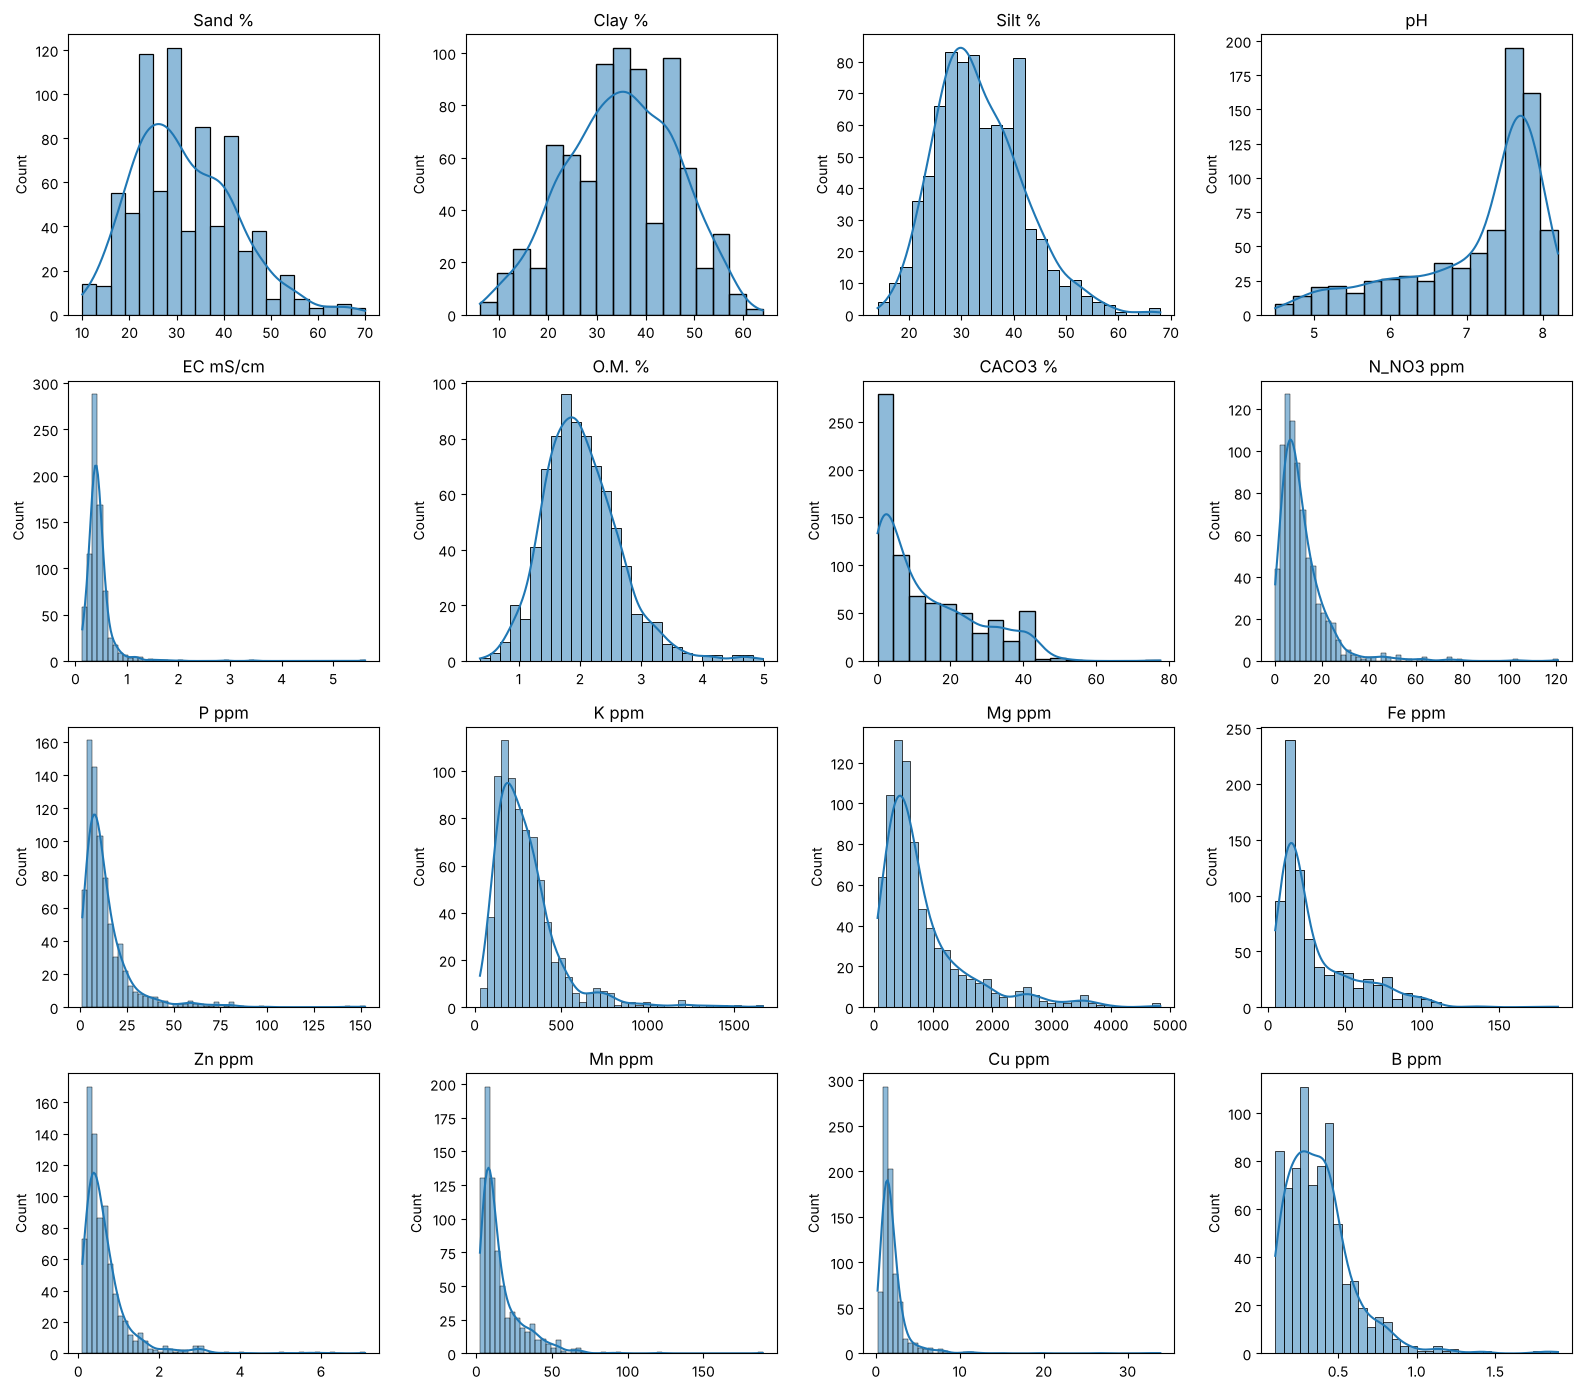

In [6]:
numerical_columns = data.select_dtypes(include=[np.number]).columns

n = len(numerical_columns)
ncols = 4
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 4, nrows * 3.5))
axes = axes.flatten()

for ax, column in zip(axes, numerical_columns):
    sns.histplot(data[column], kde=True, ax=ax)
    ax.set_title(column)
    ax.set_xlabel('')

for ax in axes[n:]:
    ax.axis('off')

plt.tight_layout()
plt.show()

In [7]:
print("Skewness (sorted):")
print(data[numerical_columns].skew().sort_values(ascending=False))

Skewness (sorted):
EC mS/cm     8.870008
Cu ppm       7.809563
Zn ppm       4.329918
P ppm        3.910385
N_NO3 ppm    3.838832
Mn ppm       3.615259
K ppm        2.589166
Mg ppm       2.103376
B ppm        2.034692
Fe ppm       1.707067
CACO3 %      0.953486
O.M. %       0.865790
Silt %       0.664757
Sand %       0.599985
Clay %      -0.103175
pH          -1.173369
dtype: float64


**Insights:**
- `pH` is left-skewed: most soils are neutral to alkaline (median 7.55) and it never goes above 8.2, which is typical of carbonate-rich soils.
- `EC`, `Cu`, `Zn`, `P`, `N_NO3` and `Mn` are heavily right-skewed: a few samples have very high values.
- Sand, Clay and organic matter are close to symmetric.

## Bivariate Analysis (each feature vs. pH)

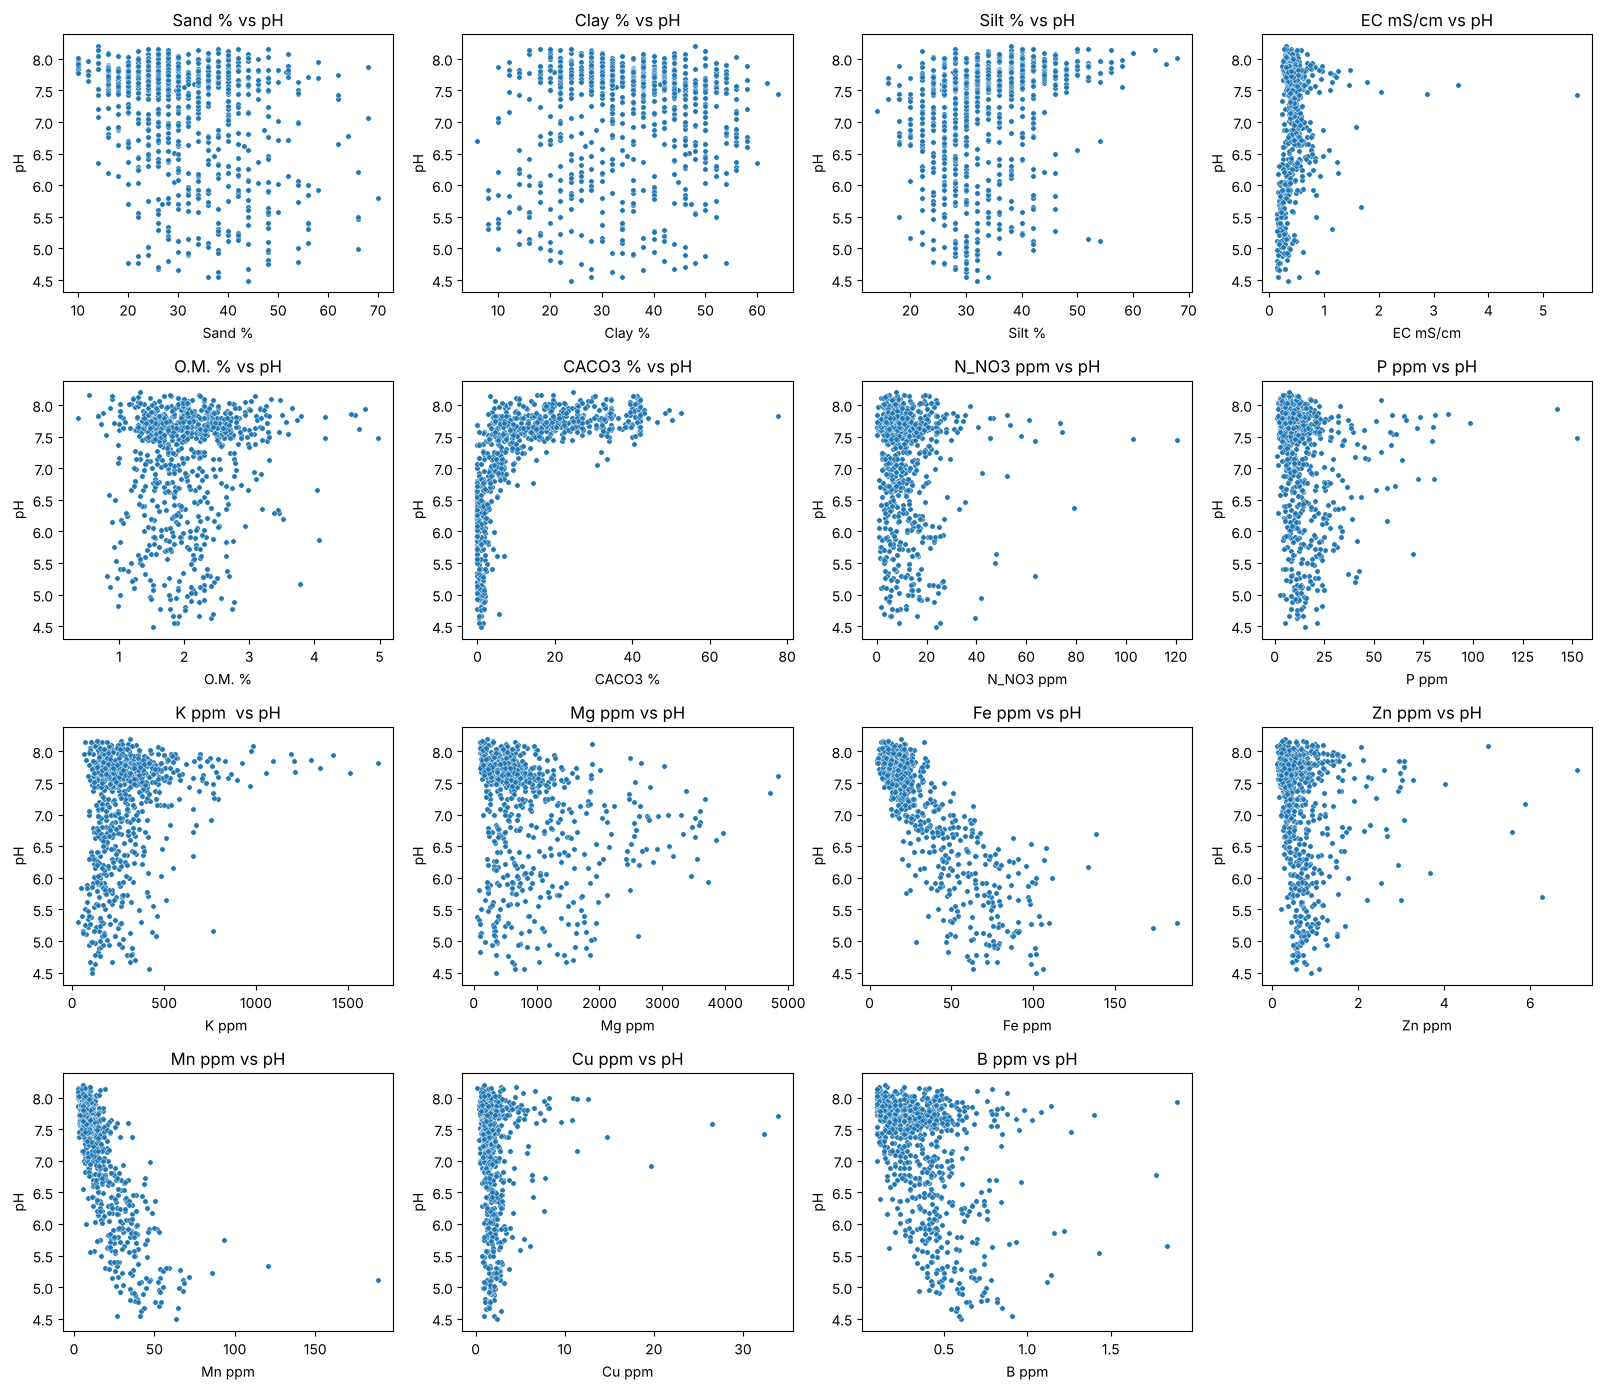

In [8]:
predictor_columns = [c for c in numerical_columns if c != TARGET]

ncols = 4
nrows = int(np.ceil(len(predictor_columns) / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 4, nrows * 3.5))
axes = axes.flatten()

for ax, column in zip(axes, predictor_columns):
    sns.scatterplot(data=data, x=column, y=TARGET, ax=ax, s=15)
    ax.set_title(f'{column} vs {TARGET}')

for ax in axes[len(predictor_columns):]:
    ax.axis('off')

plt.tight_layout()
plt.show()

**Insights:**
- `Fe` and `Mn` clearly go down as pH goes up (acidic soil dissolves them, alkaline soil locks them).
- `CaCO3` goes up with pH, but it levels off near 8.2, so the trend is curved.
- Organic matter, Cu, P, EC and Zn show almost no relationship with pH.

## Multivariate Analysis

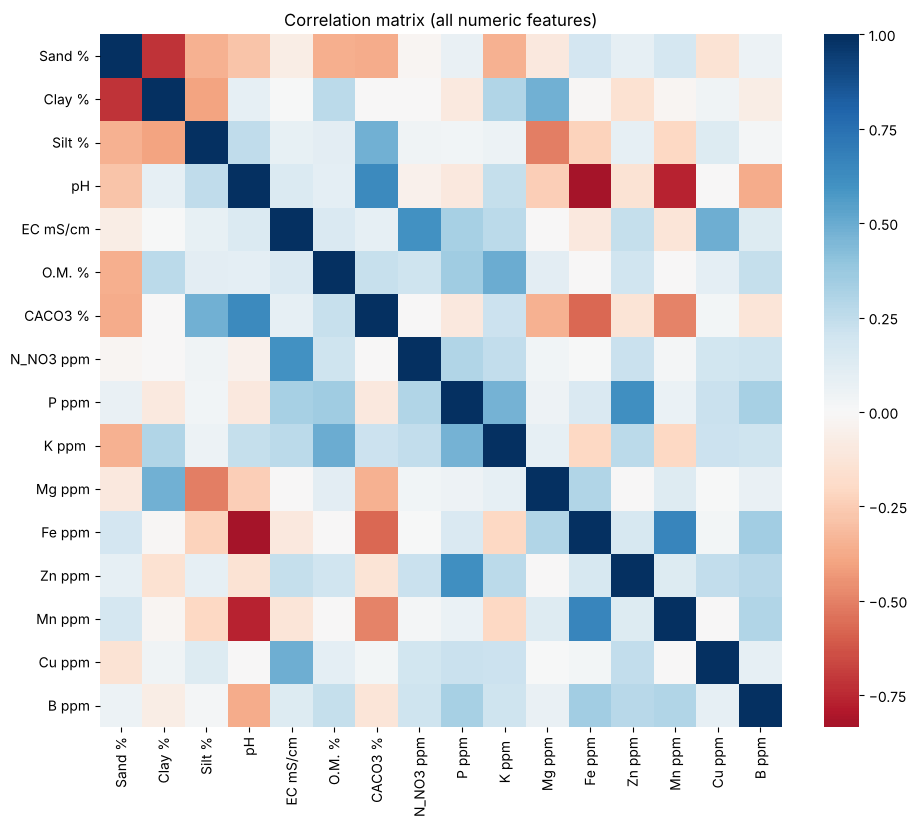

Correlation with pH, sorted:
CACO3 %      0.629028
Silt %       0.247951
K ppm        0.235894
EC mS/cm     0.143590
O.M. %       0.103756
Clay %       0.095765
Cu ppm      -0.002753
N_NO3 ppm   -0.051873
P ppm       -0.106706
Zn ppm      -0.139978
Mg ppm      -0.244688
Sand %      -0.287516
B ppm       -0.372534
Mn ppm      -0.767299
Fe ppm      -0.834923
Name: pH, dtype: float64


In [9]:
plt.figure(figsize=(11, 9))
corr = data.corr(numeric_only=True)
sns.heatmap(corr, cmap='RdBu', center=0, annot=False)
plt.title('Correlation matrix (all numeric features)')
plt.show()

print(f"Correlation with {TARGET}, sorted:")
print(corr[TARGET].drop(TARGET).sort_values(ascending=False))

In [10]:
# Strongest correlations between the predictors themselves
pred_corr = corr.drop(index=TARGET, columns=TARGET).abs()
pairs = pred_corr.where(np.triu(np.ones(pred_corr.shape), k=1).astype(bool)).stack().sort_values(ascending=False)
pairs.head(8).round(3)

Sand %    Clay %       0.716
Fe ppm    Mn ppm       0.660
P ppm     Zn ppm       0.612
EC mS/cm  N_NO3 ppm    0.602
CACO3 %   Fe ppm       0.575
Silt %    Mg ppm       0.512
O.M. %    K ppm        0.496
CACO3 %   Mn ppm       0.494
dtype: float64

**Insights:**
- Strongest links with pH: `Fe` (-0.83), `Mn` (-0.77) and `CaCO3` (+0.63).
- Predictors are only moderately correlated with each other (Sand-Clay 0.72, Fe-Mn 0.66), so multicollinearity is not a big problem.

## Outlier Analysis

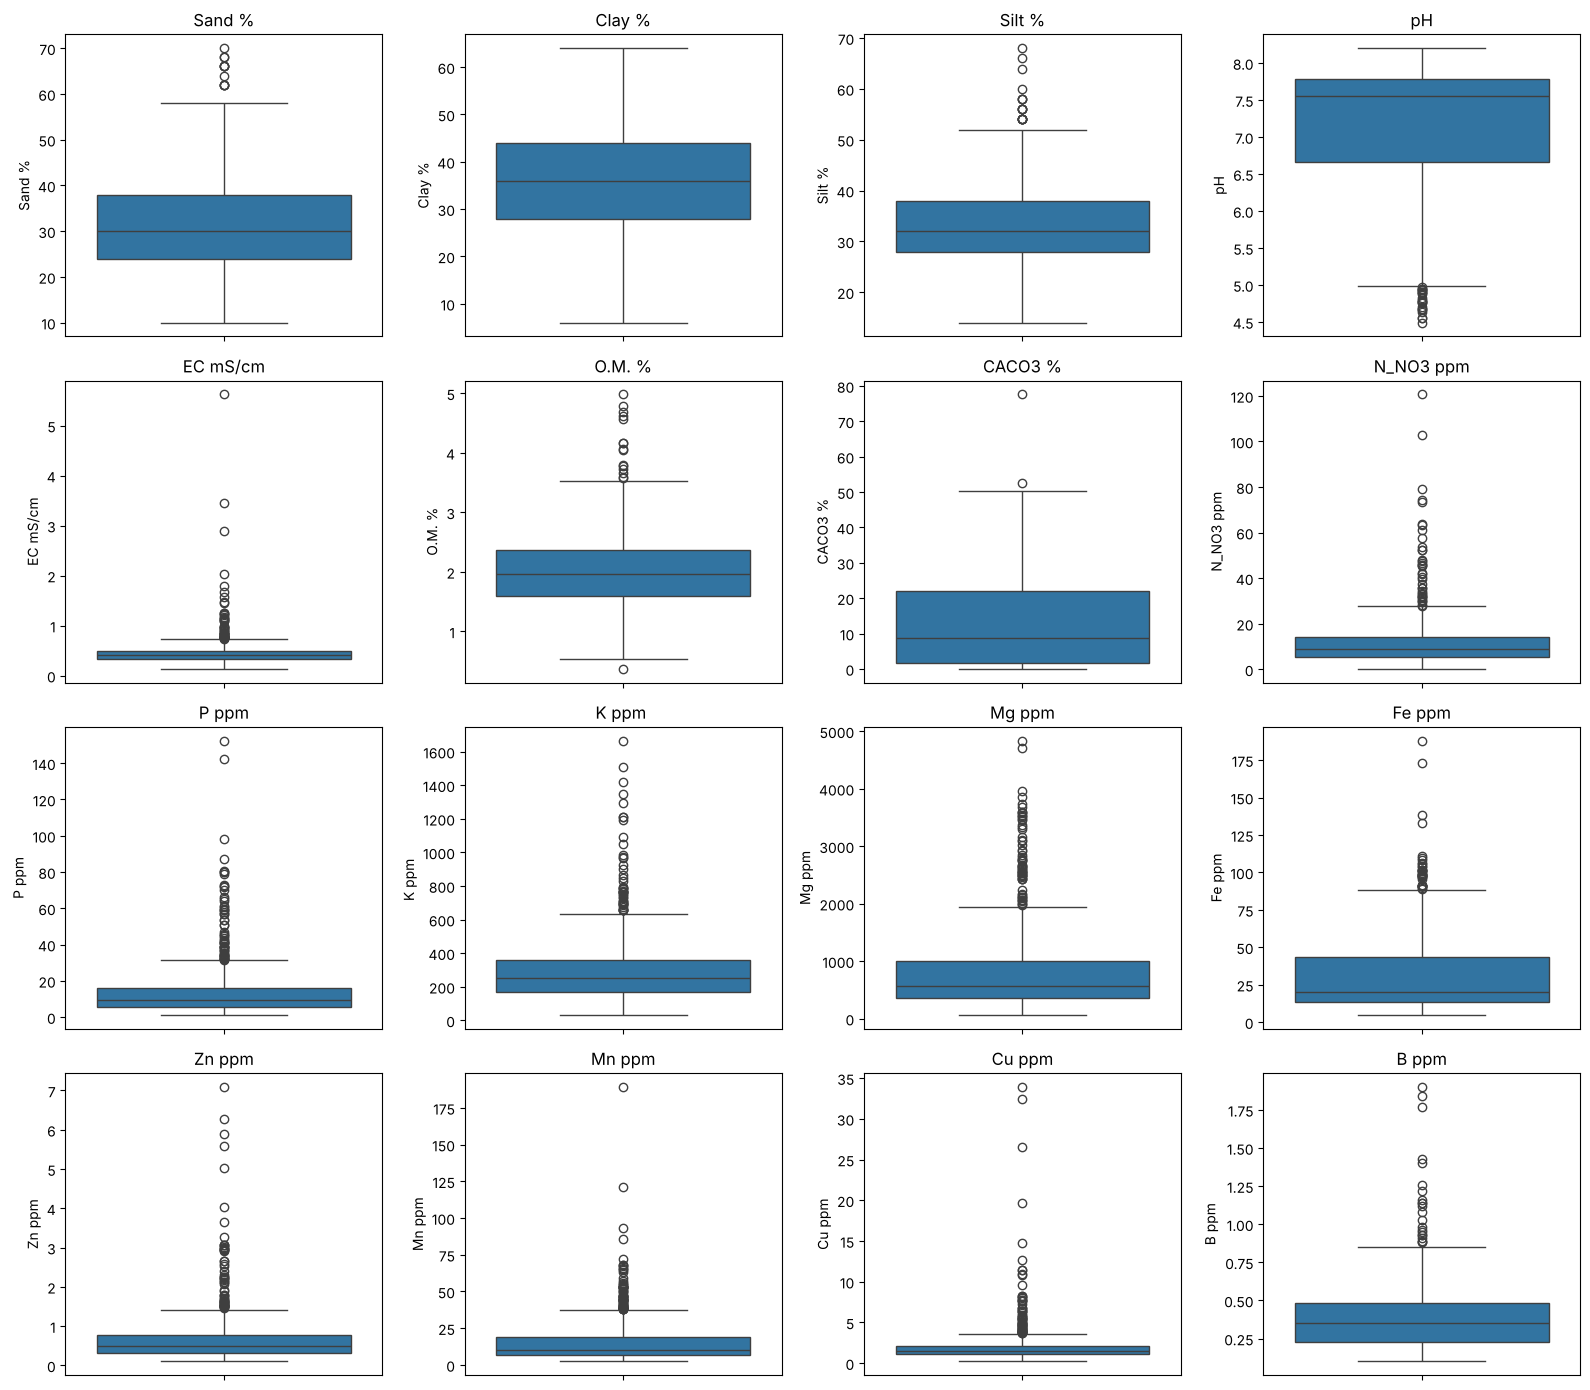

Number of IQR outliers per column:
Mn ppm       65
Cu ppm       64
Mg ppm       61
P ppm        60
Zn ppm       59
EC mS/cm     51
K ppm        45
N_NO3 ppm    37
Fe ppm       34
pH           23
B ppm        22
Silt %       17
O.M. %       16
Sand %       12
CACO3 %       2
Clay %        0
dtype: int64


In [11]:
def iqr_outliers(col):
    Q1, Q3 = data[col].quantile([0.25, 0.75])
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5*IQR, Q3 + 1.5*IQR
    return data[(data[col] < lower) | (data[col] > upper)]

nrows = int(np.ceil(len(numerical_columns) / 4))
fig, axes = plt.subplots(nrows, 4, figsize=(16, 3.5 * nrows))
axes = axes.flatten()
for ax, col in zip(axes, numerical_columns):
    sns.boxplot(y=data[col], ax=ax)
    ax.set_title(col)
for ax in axes[len(numerical_columns):]:
    ax.axis('off')

plt.tight_layout()
plt.show()

print("Number of IQR outliers per column:")
print(pd.Series({c: len(iqr_outliers(c)) for c in numerical_columns}).sort_values(ascending=False))

**Insights:**
- `Mn`, `Cu`, `Mg`, `P` and `Zn` have the most outliers (around 60 each).
- They are real soil values, not errors, so we keep them and don't clip anything.
- Random Forest isn't affected by extreme values, but Linear Regression and SVR are, which should favour Random Forest.

## Train / Test Split

`Silt %` is dropped because Sand + Clay + Silt = 100 (it is fully known from the other two). The split comes before filling and scaling, so the test set stays untouched.

In [12]:
from sklearn.model_selection import train_test_split

X = data.drop(columns=[TARGET, 'Silt %'])
y = data[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(X_train.shape, X_test.shape)

(624, 14) (157, 14)


## Missing Values (train medians only)

In [13]:
train_medians = X_train.median()
X_train_imp = X_train.fillna(train_medians)
X_test_imp = X_test.fillna(train_medians)

print("Missing left in train:", X_train_imp.isnull().sum().sum())
print("Missing left in test:", X_test_imp.isnull().sum().sum())

Missing left in train: 0
Missing left in test: 0


## Feature Scaling

Linear, Ridge and SVR need scaled data. Random Forest doesn't, so it uses the unscaled data. The scaler is fitted on train only.

In [14]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train_imp), columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test_imp), columns=X_test.columns, index=X_test.index)

## Models

In [15]:
from sklearn.metrics import mean_squared_error, r2_score

def print_metrics(model, X_train_, y_train_, X_test_, y_test_, y_pred):
    mse = mean_squared_error(y_test_, y_pred)
    print(f"Mean Squared Error: {mse:.3f}")
    print(f"Root Mean Squared Error: {mse ** 0.5:.3f}")
    print(f"R-squared: {r2_score(y_test_, y_pred):.3f}")
    print(f"Train set score: {model.score(X_train_, y_train_):.3f}")
    print(f"Test set score: {model.score(X_test_, y_test_):.3f}")

## Linear Regression

In [16]:
from sklearn.linear_model import LinearRegression

lin_model = LinearRegression()
lin_model.fit(X_train_scaled, y_train)
y_pred = lin_model.predict(X_test_scaled)
print_metrics(lin_model, X_train_scaled, y_train, X_test_scaled, y_test, y_pred)

Mean Squared Error: 0.176
Root Mean Squared Error: 0.419
R-squared: 0.808
Train set score: 0.820
Test set score: 0.808


## Ridge

In [17]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV

param_grid_ridge = {'alpha': [0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0, 20.0, 50.0, 100.0, 200.0]}

ridge_search = GridSearchCV(Ridge(), param_grid_ridge, cv=5,
                             scoring='neg_mean_squared_error', n_jobs=-1)
ridge_search.fit(X_train_scaled, y_train)
print("Best alpha (Ridge): ", ridge_search.best_params_)

ridge_model = ridge_search.best_estimator_
y_pred = ridge_model.predict(X_test_scaled)
print_metrics(ridge_model, X_train_scaled, y_train, X_test_scaled, y_test, y_pred)

Best alpha (Ridge):  {'alpha': 50.0}
Mean Squared Error: 0.175
Root Mean Squared Error: 0.418
R-squared: 0.808
Train set score: 0.818
Test set score: 0.808


**Insights:**
- Linear and Ridge give almost the same result, and neither is great. Straight lines can't capture curved relationships like `CaCO3` vs pH.
- Train and test scores are close, so this is underfitting, not overfitting.

## Random Forest

In [18]:
from sklearn.ensemble import RandomForestRegressor

param_grid_rf = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 7, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2'],
}

rf_search = GridSearchCV(RandomForestRegressor(random_state=42), param_grid_rf, cv=5,
                          scoring='neg_mean_squared_error', n_jobs=-1)
rf_search.fit(X_train_imp, y_train)
print("Best parameters found (Random Forest): ", rf_search.best_params_)

rf_model = rf_search.best_estimator_
y_pred = rf_model.predict(X_test_imp)
print_metrics(rf_model, X_train_imp, y_train, X_test_imp, y_test, y_pred)

Best parameters found (Random Forest):  {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 300}
Mean Squared Error: 0.094
Root Mean Squared Error: 0.306
R-squared: 0.898
Train set score: 0.985
Test set score: 0.898


**Insights:**
- Random Forest is clearly better than the linear models: RMSE about 0.31 and R-squared about 0.90.
- Train score is much higher than test score, which is normal for Random Forest. The CV error is almost the same as the test error, so it still generalises well.

## Support Vector Regression (SVR)

SVR uses the scaled data, like the linear models.

In [19]:
from sklearn.svm import SVR

param_grid_svr = {
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 0.01, 0.1],
    'epsilon': [0.01, 0.1, 0.2],
    'kernel': ['rbf'],
}

svr_search = GridSearchCV(SVR(), param_grid_svr, cv=5,
                           scoring='neg_mean_squared_error', n_jobs=-1)
svr_search.fit(X_train_scaled, y_train)
print("Best parameters found (SVR): ", svr_search.best_params_)

svr_model = svr_search.best_estimator_
y_pred = svr_model.predict(X_test_scaled)
print_metrics(svr_model, X_train_scaled, y_train, X_test_scaled, y_test, y_pred)

Best parameters found (SVR):  {'C': 10, 'epsilon': 0.2, 'gamma': 0.01, 'kernel': 'rbf'}
Mean Squared Error: 0.112
Root Mean Squared Error: 0.335
R-squared: 0.877
Train set score: 0.911
Test set score: 0.877


**Insights:**
- SVR is much better than the linear models because it can fit curves, but it still stays behind Random Forest (RMSE about 0.34 vs 0.31).
- It is also more affected by the outliers, since we didn't clip them.

## Comparing Models

We compare cross-validated RMSE (on train only) and test RMSE.

In [20]:
from sklearn.model_selection import KFold, cross_val_score

kf = KFold(n_splits=5, shuffle=True, random_state=42)

# name: (model, uses_scaled_data)
all_models = {
    "Linear Regression": (lin_model, True),
    "Ridge": (ridge_model, True),
    "Random Forest": (rf_model, False),
    "SVR": (svr_model, True),
}

rows = []
for name, (model, scaled) in all_models.items():
    Xtr = X_train_scaled if scaled else X_train_imp
    Xte = X_test_scaled if scaled else X_test_imp
    cv_rmse = (-cross_val_score(model, Xtr, y_train, cv=kf, scoring='neg_mean_squared_error')).mean() ** 0.5
    pred = model.predict(Xte)
    rows.append({
        "Model": name,
        "CV RMSE (train)": cv_rmse,
        "Test RMSE": mean_squared_error(y_test, pred) ** 0.5,
        "Test R2": r2_score(y_test, pred),
    })

results = pd.DataFrame(rows).sort_values("CV RMSE (train)").reset_index(drop=True)
results.round(4)

,Model,CV RMSE (train),Test RMSE,Test R2
0,Random Forest,0.2953,0.3058,0.8975
1,SVR,0.3198,0.3350,0.8770
2,Ridge,0.4016,0.4183,0.8082
3,Linear Regression,0.4153,0.4190,0.8076


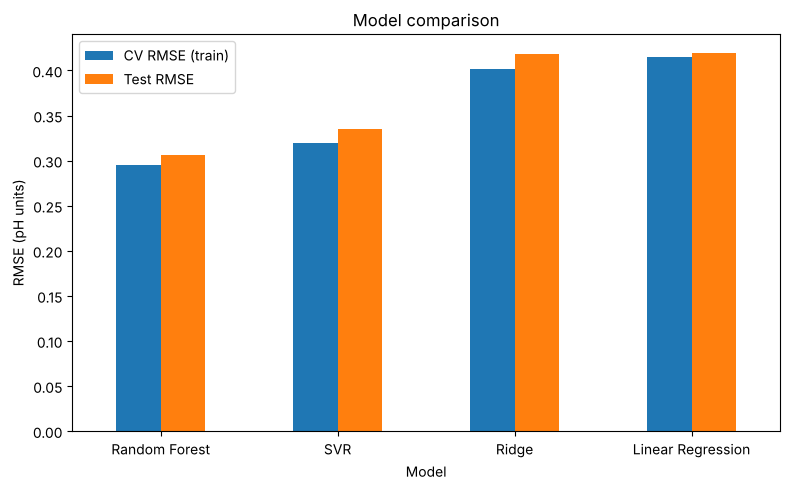

In [21]:
results.set_index('Model')[['CV RMSE (train)', 'Test RMSE']].plot(kind='bar', figsize=(8, 5))
plt.ylabel('RMSE (pH units)')
plt.title('Model comparison')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Insights:**
- Random Forest is the best model on both CV and test RMSE, followed by SVR, then Ridge and Linear Regression.
- The non-linear models cut the error by roughly a quarter compared with the linear ones.
- CV and test RMSE are close for every model, so nothing is badly overfitted.

## Final Model & Test Evaluation

The final model is the one with the lowest CV RMSE. The test set is used only once, to report the final score.

In [22]:
final_name = results.loc[0, 'Model']
final_model, final_scaled = all_models[final_name]
final_X_test = X_test_scaled if final_scaled else X_test_imp
print("Final model:", final_name)

y_pred = final_model.predict(final_X_test)

from sklearn.metrics import mean_absolute_error
print(f"Test R2:   {r2_score(y_test, y_pred):.3f}")
print(f"Test RMSE: {mean_squared_error(y_test, y_pred) ** 0.5:.3f}  (pH units)")
print(f"Test MAE:  {mean_absolute_error(y_test, y_pred):.3f}  (pH units)")

Final model: Random Forest
Test R2:   0.898
Test RMSE: 0.306  (pH units)
Test MAE:  0.218  (pH units)


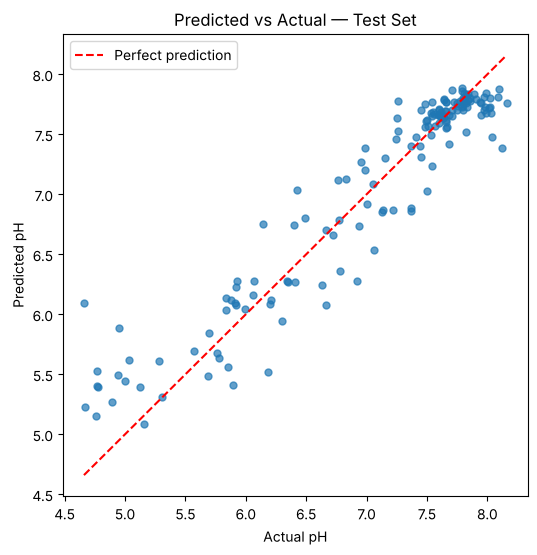

In [23]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, s=25, alpha=0.7)
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, 'r--', label='Perfect prediction')
plt.xlabel('Actual pH')
plt.ylabel('Predicted pH')
plt.title('Predicted vs Actual — Test Set')
plt.legend()
plt.show()

**Insights:**
- Random Forest predicts pH with an RMSE of about 0.31 and R-squared about 0.90, so it explains roughly 90% of the variation in pH.
- On average it is off by about 0.22 pH units, and most predictions are within 0.5 of the real value.
- It is least accurate for acidic soils (pH below 6): there are fewer of them in the data, and the model tends to over-predict them.
- `Fe` and `Mn` depend on pH, not the other way round, so the model estimates pH well but doesn't explain what causes it.